In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.pipeline import Pipeline
# Preprocesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Selección de características
from sklearn.feature_selection import SequentialFeatureSelector

# Reducción de dimensionalidad
from sklearn.decomposition import PCA

# Model selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

# Métricas
from sklearn.metrics import accuracy_score, classification_report, recall_score, roc_auc_score, roc_curve, auc, confusion_matrix, f1_score, precision_score

# Pipelines y balanceo
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as IMBPIPELINE 
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from sklearn.cluster import KMeans
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

#Torch
# import torch
# import torch.nn as nn
# from torch.utils.data import DataLoader, TensorDataset

# from sklearn.base import BaseEstimator, ClassifierMixin

In [54]:
churn_train = pd.read_csv('churn_train_clean.csv')
churn_test = pd.read_csv('churn_test_clean.csv')
X_train = churn_train.drop(columns='Churn Value')
Y_train = churn_train['Churn Value']
X_test = churn_test.drop(columns='Churn Value')
Y_test = churn_test['Churn Value']

In [55]:
numerical_cols = ["Total Charges", "Monthly Charges", "Tenure Months", "CLTV"]
categorical_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]

# RANDOM FOREST

In [56]:
# Preprocesador para las transformaciones de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


# Pipeline con el preprocesador, el balanceo y el modelo

pipeline_rf = IMBPIPELINE([
    ("preprocessor", preprocessor),         # transformar datos
    ("oversample", RandomOverSampler(random_state=10)),  # balancear clases
    ("rf", RandomForestClassifier(random_state=10))
])


# Parámetros a probar por el modelo
param_grid = {
    "rf__n_estimators": [25,50,75,100,125,150,175,200,225,250,275,300],
    "rf__max_depth": [1,2,3,4,5,6,7,8,9,10]
    }

#Grid search (también hemos probado la función de Randomized Search pero consigue peores resultados en test y resultados similares o inferiores en CV)
grid_search = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    verbose=1,
    n_jobs=-1
)
print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, Y_train)
print("GridSearch completo.\n")

print("Mejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score CV (F1): {grid_search.best_score_:.4f}")


#Evaluación final en test
best_model_rf = grid_search.best_estimator_
y_pred_rf = best_model_rf.predict(X_test)
y_prob_rf = best_model_rf.predict_proba(X_test)[:, 1]  # solo la probabilidad de la clase 1
fpr_rf, tpr_rf, thresholds_rf = roc_curve(Y_test, y_prob_rf)


print("\n=== REPORTE FINAL EN TEST ===")
print(classification_report(Y_test, y_pred_rf))

final_recall = recall_score(Y_test, y_pred_rf)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 3 folds for each of 120 candidates, totalling 360 fits
GridSearch completo.

Mejores parámetros encontrados:
{'rf__max_depth': 8, 'rf__n_estimators': 200}

Mejor score CV (F1): 0.6469

=== REPORTE FINAL EN TEST ===
              precision    recall  f1-score   support

           0       0.91      0.75      0.83      1294
           1       0.54      0.81      0.65       467

    accuracy                           0.77      1761
   macro avg       0.73      0.78      0.74      1761
weighted avg       0.82      0.77      0.78      1761

Recall Final en TEST: 0.8051


# XGBOOST

In [57]:
# Preprocesador para las transformaciones de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


# Pipeline con el preprocesador, el balanceo y el modelo

pipeline_xgb = IMBPIPELINE([
    ("preprocessor", preprocessor),        
    ("oversample", RandomOverSampler(random_state=10)),  
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=10,
        n_jobs=-1,
        learning_rate = 0.1
    ))
])

# Parámetros a probar por el modelo
param_grid = {
    "xgb__n_estimators": [25,50,75,100,125,150,175,200,300],
    "xgb__max_depth": [1,2,3,4,5,6,7,8],
}


#Grid search (También se ha probado la función Randomized Search pero da ligeramente peores resultados en test y resultados similares en CV)

grid_search = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    verbose=1,
    n_jobs=-1
)

print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, Y_train)
print("GridSearch completo.\n")

print("Mejores parámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor score CV (Recall): {grid_search.best_score_:.4f}")



#Evaluación final en test

best_model_xg = grid_search.best_estimator_
y_pred_xgb = best_model_xg.predict(X_test)

y_prob_xg = best_model_xg.predict_proba(X_test)[:, 1]  # solo la probabilidad de la clase 1
fpr_xg, tpr_xg, thresholds_xg = roc_curve(Y_test, y_prob_xg)

print("\n=== REPORTE FINAL EN TEST ===")
print(classification_report(Y_test, y_pred_xgb))

final_recall = recall_score(Y_test, y_pred_xgb)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando GridSearchCV...
Fitting 3 folds for each of 72 candidates, totalling 216 fits
GridSearch completo.

Mejores parámetros encontrados:
{'xgb__max_depth': 1, 'xgb__n_estimators': 300}

Mejor score CV (Recall): 0.6453

=== REPORTE FINAL EN TEST ===
              precision    recall  f1-score   support

           0       0.92      0.73      0.81      1294
           1       0.53      0.83      0.64       467

    accuracy                           0.76      1761
   macro avg       0.72      0.78      0.73      1761
weighted avg       0.82      0.76      0.77      1761

Recall Final en TEST: 0.8266


# Naive Bayes Gaussiano

In [58]:
# Procesador de columnas

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

# Pipeline con preprocesador, balanceo y modelo

pipeline_nb = IMBPIPELINE([
    ("preprocessor", preprocessor),
    ("undersampler", RandomOverSampler(random_state=10)),
    ("nb", GaussianNB())
])


print("Ejecutando Cross-Validation (CV=5)...")
cv_scores = cross_val_score(
    pipeline_nb, 
    X_train,      # aquí usamos directamente X_train
    Y_train,
    cv=3, 
    scoring='f1', 
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando GaussianNB con oversampling sobre todo el train...")
pipeline_nb.fit(X_train, Y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred_nb = pipeline_nb.predict(X_test)
y_prob_nb = pipeline_nb.predict_proba(X_test)[:, 1]  # solo la probabilidad de la clase 1
fpr_nb, tpr_nb, thresholds_nb = roc_curve(Y_test, y_prob_nb)

print("\n=== REPORTE FINAL ===")
print(classification_report(Y_test, y_pred_nb))

final_recall = recall_score(Y_test, y_pred_nb)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5)...
F1 promedio en CV: 0.6274
Desviación estándar en CV: 0.0087

Entrenando GaussianNB con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.79      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.80      0.75      0.76      1761

Recall Final en TEST: 0.7944


# Regresión logística

In [59]:

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


pipeline_nb = IMBPIPELINE([
    ("preprocessor", preprocessor),
    ("undersampler", RandomOverSampler(random_state=10)),
    ("nb", LogisticRegression(random_state=10))
])


print("Ejecutando Cross-Validation (CV=5)...")
cv_scores = cross_val_score(
    pipeline_nb, 
    X_train,     
    Y_train,
    cv=3, 
    scoring='f1', 
    n_jobs=-1
)

print(f"F1 promedio en CV: {cv_scores.mean():.4f}")
print(f"Desviación estándar en CV: {cv_scores.std():.4f}")

# ============================================================
# Entrenamiento final sobre todo el train
# ============================================================

print("\nEntrenando regrersion logistica con oversampling sobre todo el train...")
pipeline_nb.fit(X_train, Y_train)
print("Entrenamiento completado.")

# ============================================================
# Predicción en test
# ============================================================

y_pred_rl = pipeline_nb.predict(X_test)
y_prob_rl = pipeline_nb.predict_proba(X_test)[:, 1]  # solo la probabilidad de la clase 1
fpr_rl, tpr_rl, thresholds_rl = roc_curve(Y_test, y_prob_rl)


print("\n=== REPORTE FINAL ===")
print(classification_report(Y_test, y_pred_rl))

final_recall = recall_score(Y_test, y_pred_rl)
print(f"Recall Final en TEST: {final_recall:.4f}")


Ejecutando Cross-Validation (CV=5)...
F1 promedio en CV: 0.6355
Desviación estándar en CV: 0.0069

Entrenando regrersion logistica con oversampling sobre todo el train...
Entrenamiento completado.

=== REPORTE FINAL ===
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1294
           1       0.52      0.80      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.81      0.75      0.76      1761

Recall Final en TEST: 0.7966


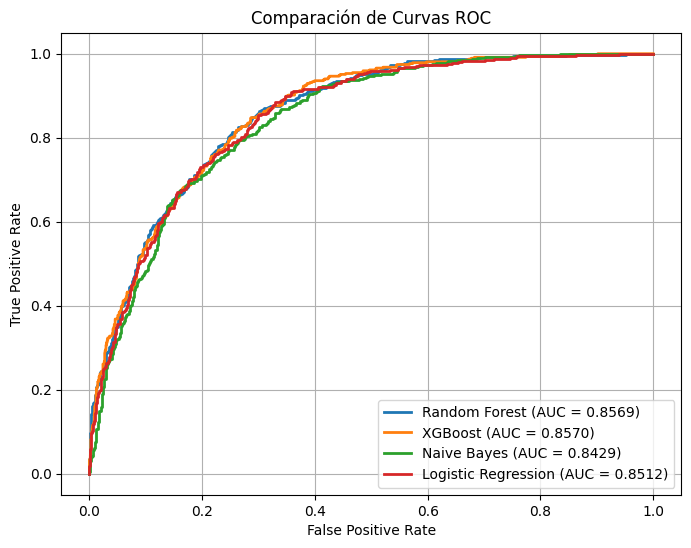

In [60]:

roc_auc_rf = auc(fpr_rf, tpr_rf)
roc_auc_xgb = auc(fpr_xg, tpr_xg)
roc_auc_nb = auc(fpr_nb, tpr_nb)
roc_auc_rl = auc(fpr_rl, tpr_rl)

plt.figure(figsize=(8,6))

# Dibujar curvas ROC
plt.plot(fpr_rf, tpr_rf, lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.4f})')
plt.plot(fpr_xg, tpr_xg, lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.4f})')
plt.plot(fpr_nb, tpr_nb, lw=2, label=f'Naive Bayes (AUC = {roc_auc_nb:.4f})')
plt.plot(fpr_rl, tpr_rl, lw=2, label=f'Logistic Regression (AUC = {roc_auc_rl:.4f})')


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparación de Curvas ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


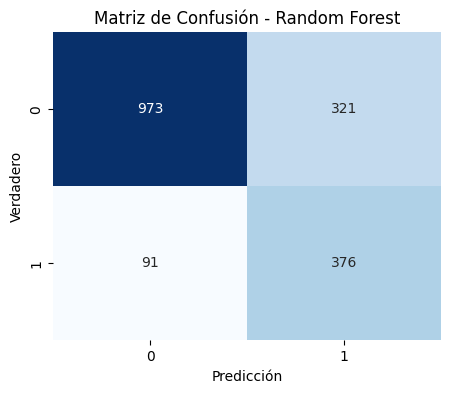

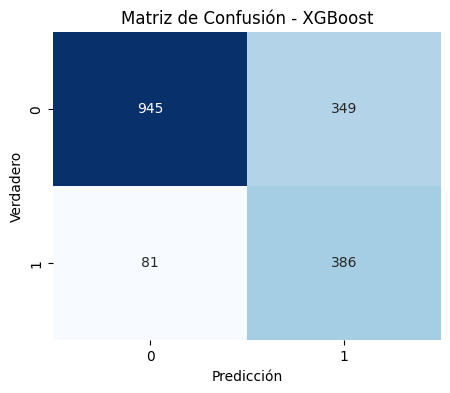

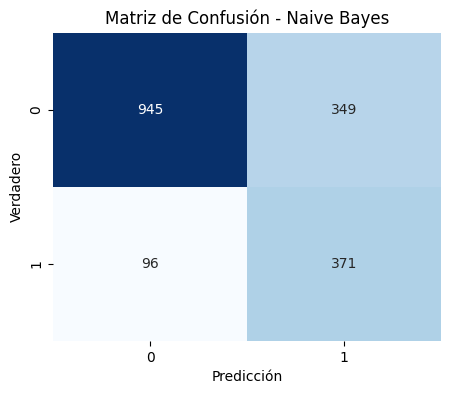

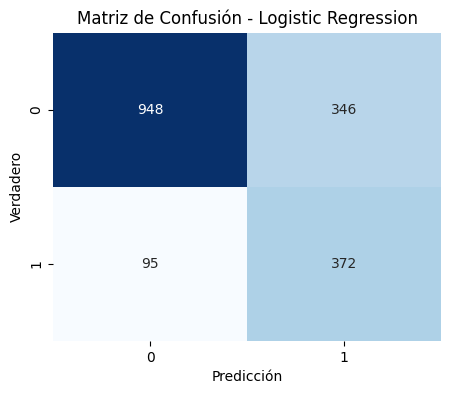

In [61]:
model_names = ['Random Forest', 'XGBoost', 'Naive Bayes', 'Logistic Regression']
y_preds = [y_pred_rf, y_pred_xgb, y_pred_nb, y_pred_rl]


for name, y_pred in zip(model_names, y_preds):
    cm = confusion_matrix(Y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Matriz de Confusión - {name}')
    plt.xlabel('Predicción')
    plt.ylabel('Verdadero')
    plt.show()


## Redes Neuronales

**Implementaciones:**

-   Gaussian Dropout: lo elegimos porque regulariza sin “apagar” las neuronas como el dropout convencional. En vez de poner activaciones a 0, mete ruido alrededor de 1, lo que ayuda a generalizar sin perder tanta capacidad.

-   Residual connections: las usamos para que el entrenamiento sea más estable y para que el modelo pueda aprender “correcciones” capa a capa. Facilita el flujo del gradiente cuando hay varias capas.

-   ReLU: activación simple y efectiva para introducir no linealidad sin complicaciones.

-   BCEWithLogitsLoss + pos_weight: para penalizar más los errores en la clase churn (minoritaria) y empujar el modelo a detectar mejor los que se van.

-   Learning rate scheduler: para bajar el learning rate durante el entrenamiento y evitar pasarnos del mínimo. Suele converger de manera más suave que un LR fijo.

-   Oversampling en el pipeline: para equilibrar clases durante el entrenamiento y evitar que el modelo aprenda a decir casi siempre churn = 0.

-    Umbral de threshold ajustable: el 0.5 no siempre es óptimo. Al mover el umbral, esto nos permite subir recall o equilibrar con precisión según el objetivo.

In [62]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, recall_score, precision_score, f1_score

def to01(y):
    y = np.array(y).reshape(-1) #Convertimos el vector y a numpy y lo transformamos en un vector 1d

    if y.dtype == object: #Por si acaso lo recibe como un objeto, para evitar complicaciones

        y = np.where((y == "Yes") | (y == "yes") | (y == True) | (y == 1), 1, 0) #Si cumple, 1, sino cumple, 0

    return y.astype(int)

#Llamamos a la función tod01 para transformar los datos

Y_train01 = to01(Y_train)
Y_test01  = to01(Y_test)

#Preprocesador 
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


## Por si acaso necesitamos correr el código con la GPU con google collab

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

#Creamos el dropout para añadir ruido gaussiano multiplicativo a las neuronas
class GaussianDropout(nn.Module):
    def __init__(self, p=0.15):
        super().__init__()
        self.p = float(p)
    def forward(self, x):
        if (not self.training) or self.p <= 0:
            return x
        
        #Definimos la desviación típica
        std = (self.p / (1.0 - self.p)) ** 0.5

        #Definimos el ruido
        noise = torch.randn_like(x) * std + 1.0
        return x * noise

##Definimos una red neuronal simple, con 128 dimensiones ocultas, 3 capas ocultas y con un dropout gaussiano de 0.15 moderado
class SimpleResidualFC(nn.Module):
    def __init__(self, dim_in, hidden_dim=128, n_layers=3, dropout=0.15):
        super().__init__()
        self.blocks = nn.ModuleList([]) #Definimos los bloques como un nn.ModuleList
        in_dim = dim_in #Dimensiones de entrada

        #Forward -> Función de activación -> Dropout
        for _ in range(n_layers):
            self.blocks.append(nn.Sequential(
                nn.Linear(in_dim, hidden_dim), #Forward con input: in_dim, y output: hidden_dim
                nn.ReLU(), #Función de activación lineal 
                GaussianDropout(dropout) #Dropout gaussiano
            ))
            in_dim = hidden_dim

            #En la última capa, no aplicamos RELU ni Dropout, 
        self.out = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out = x
        prev = x
        for block in self.blocks:
            out = block(out)
            if out.shape == prev.shape:   # residual solo si encajan las shapes
                out = out + prev #Definimos el residual
            prev = out
        return self.out(out)  


##Ahora definimos una clase de wrapper, que hará que la red se comporte como un modelo de skicit-learn para poder aplicarle el searchgrid
# Base estimator hace que skicit-lean pueda leer y guardar los hiperparámetros que declaremos en el init y permite cosas como el get_params() que luego se usa en el GridSearch
# ClassifierMixin le indica a skicit - learn que es un clasificador

class TorchNNClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden_dim=128, n_layers=3, dropout=0.15, lr=0.05, epochs=12, batch_size=256, thr=0.35):
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.dropout = dropout
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.thr = thr

    # Matriz con datos de float32 guardados 

    def _dense32(self, X):
        if hasattr(X, "toarray"):  # Condicion: Tiene X el método .toarray()??
            X = X.toarray()
        return np.asarray(X).astype(np.float32)

    def fit(self, X, y):
        X = self._dense32(X)
        y = to01(y).astype(np.float32).reshape(-1, 1)

        X_t = torch.tensor(X, dtype=torch.float32)
        y_t = torch.tensor(y, dtype=torch.float32)

        ds = TensorDataset(X_t, y_t)
        dl = DataLoader(ds, batch_size=self.batch_size, shuffle=True)

        self.model_ = SimpleResidualFC(
            dim_in=X.shape[1],
            hidden_dim=self.hidden_dim,
            n_layers=self.n_layers,
            dropout=self.dropout
        ).to(device)

        # pos_weight simple (ayuda a recall)
        y_int = y.reshape(-1)
        pos = float(y_int.sum())
        neg = float(len(y_int) - y_int.sum())
        pos_weight = torch.tensor([neg / (pos + 1e-9)], device=device)

        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        opt = torch.optim.SGD(self.model_.parameters(), lr=self.lr, momentum=0.9)

        self.model_.train()
        for _ in range(self.epochs):
            for xb, yb in dl:
                xb, yb = xb.to(device), yb.to(device)
                logits = self.model_(xb)
                loss = loss_fn(logits, yb)
                opt.zero_grad()
                loss.backward()
                opt.step()

        return self

    def predict_proba(self, X):
        X = self._dense32(X)
        X_t = torch.tensor(X, dtype=torch.float32).to(device)
        self.model_.eval()
        with torch.no_grad():
            logits = self.model_(X_t).detach().cpu().numpy().reshape(-1)
            p = 1.0 / (1.0 + np.exp(-logits))
        return np.vstack([1 - p, p]).T

    def predict(self, X):
        p = self.predict_proba(X)[:, 1]
        return (p >= float(self.thr)).astype(int)

## Pipeline

pipeline_nn = Pipeline([
    ("preprocessor", preprocessor),
    ("oversample", RandomOverSampler(random_state=10)),
    ("nn", TorchNNClassifier())
])


## GRIDSEARCH 

param_grid = {
    "nn__hidden_dim": [128, 256],
    "nn__n_layers":   [2, 3],
    "nn__dropout":    [0.10, 0.20],
    "nn__lr":         [0.03, 0.05],
    "nn__epochs":     [12],             
    "nn__thr":        [0.20, 0.25, 0.30, 0.35, 0.40],
}

grid_search = GridSearchCV(
    estimator=pipeline_nn,
    param_grid=param_grid,
    scoring={"recall":"recall", "precision":"precision", "f1":"f1"},
    refit="f1",     #Optimizamos f 1
    cv=4,
    verbose=1,
    n_jobs=1            
)

print("Ejecutando GridSearchCV...")
grid_search.fit(X_train, Y_train01)
print("GridSearch completo.\n")

print("Mejores parámetros encontrados (por recall):")
print(grid_search.best_params_)
print(f"\nMejor score CV (Recall): {grid_search.best_score_:.4f}")


##Definimos los mínimos (ya que es lo que hemos conseguido anteriormente con XGBOOST)
MIN_R  = 0.83
MIN_F1 = 0.63
MIN_P  = 0.52

res = pd.DataFrame(grid_search.cv_results_)

ok = (
    (res["mean_test_recall"]    >= MIN_R) &
    (res["mean_test_precision"] >= MIN_P) &
    (res["mean_test_f1"]        >= MIN_F1)
)

print("\nFILTRADO POR MÍNIMOS")
if ok.sum() == 0:
    print("Ninguna config cumple tus mínimos en MEDIA CV.")
    print("Mostrando la mejor configuración encontrada en el GridSearchCV.")
    chosen_params = grid_search.best_params_
else:
    # De las que cumplen, elige la de mayor F1 (para equilibrar)
    
    best_idx = res.loc[ok, "mean_test_f1"].idxmax()
    chosen_params = res.loc[best_idx, "params"]

    print("Config que cumple mínimos encontrada.")
    print("Params elegidos:", chosen_params)
    print("CV mean -> "
          f"P={res.loc[best_idx,'mean_test_precision']:.4f} | "
          f"R={res.loc[best_idx,'mean_test_recall']:.4f} | "
          f"F1={res.loc[best_idx,'mean_test_f1']:.4f}")


## Entrenamiento

final_model = pipeline_nn.set_params(**chosen_params)
print("\nEntrenando modelo final sobre todo el train...")
final_model.fit(X_train, Y_train01)

y_pred = final_model.predict(X_test)

print("\n=== REPORTE FINAL EN TEST ===")
print(classification_report(Y_test01, y_pred))

P_test  = precision_score(Y_test01, y_pred, zero_division=0)
R_test  = recall_score(Y_test01, y_pred, zero_division=0)
F1_test = f1_score(Y_test01, y_pred, zero_division=0)

print(f"Precision Final en TEST: {P_test:.4f}")
print(f"Recall Final en TEST:    {R_test:.4f}")
print(f"F1 Final en TEST:        {F1_test:.4f}")

OSError: [WinError 1114] Error en una rutina de inicialización de biblioteca de vínculos dinámicos (DLL). Error loading "c:\Users\david\Desktop\2\entorno\Lib\site-packages\torch\lib\c10.dll" or one of its dependencies.

## A continuación, vamos a **preparar los datos** para aplicar **K-Means** y, después, usar el **elbow method** para decidir un número razonable de clusters `k`.  




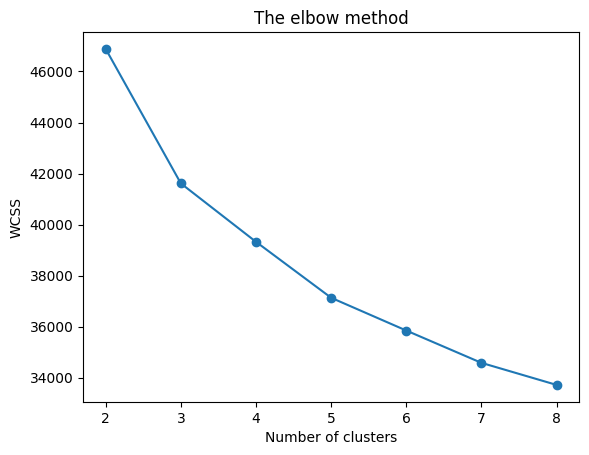

In [ ]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans

X_cluster = X_train.copy()  

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])



X_trans = preprocessor.fit_transform(X_cluster)

K = range(2, 9)
wcss = []

for k in K:
    model = KMeans(n_clusters=k, random_state=0, n_init="auto").fit(X_trans)
    wcss.append(model.inertia_)

plt.plot(list(K), wcss, marker="o")
plt.title("The elbow method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=10, n_init=10)
    labels = km.fit_predict(X_trans) 
    scores.append({
        "k": k,
        "silhouette": silhouette_score(X_trans, labels),
        "calinski_harabasz": calinski_harabasz_score(X_trans, labels),
        "davies_bouldin": davies_bouldin_score(X_trans, labels),
        "inertia": km.inertia_
    })

pd.DataFrame(scores)


,k,silhouette,calinski_harabasz,davies_bouldin,inertia
0,2,0.212546,1520.663964,1.776604,46884.521970
1,3,0.160835,1190.771206,2.041810,41614.013602
2,4,0.155080,962.668158,2.268234,39030.728560
3,5,0.131437,826.298998,2.109386,37130.906459
4,6,0.120738,727.803732,2.288095,35737.931822
5,7,0.113134,656.792730,2.363988,34565.143490
6,8,0.100251,597.934270,2.413604,33667.989993


Las métricas internas del clustering sugieren que la partición más “limpia” en términos estadísticos sería k=2, ya que maximiza la separación entre grupos. Sin embargo, convendría segmentarlo en más grupos para así tener una distinción aún más clara de los grupos con mayor probabilidad de churn. Por tanto, vamos a revisar cual de los valores de `k` tiene una menor desviación típica en las distintas inicializaciones de sus inercias (ya que dependiendo de la inicialización, estas pueden caer en un mínimo local)

In [ ]:
from sklearn.cluster import KMeans
import numpy as np
import pandas as pd

rows = []
for k in range(2, 13):
    inertias = []
    for seed in range(10):
        km = KMeans(n_clusters=k, random_state=seed, n_init=10)
        km.fit(X_trans)
        inertias.append(km.inertia_)
    rows.append({
        "k": k,
        "inertia_mean": np.mean(inertias),
        "inertia_std": np.std(inertias)
    })

pd.DataFrame(rows).sort_values("k")


,k,inertia_mean,inertia_std
0,2,46884.521970,3.253907e-12
1,3,41613.945652,9.032810e-02
2,4,39030.979631,2.888050e-01
3,5,37130.793300,2.269362e-01
4,6,35748.726216,3.249700e+01
5,7,34565.605084,3.525445e-01
6,8,33667.616094,6.053136e-01
7,9,32923.909489,1.500274e+00
8,10,32246.978111,3.145080e+01
9,11,31692.606316,2.953508e+01


Finalmente, optamos por un valor de  k = 5 ya que, aunque k = 2 es el valor más estable, ofrece una segmentación demasiado general. En cambio, k = 5 mantiene una estabilidad aceptable (sin la inestabilidad observada en k = 6), se alinea con el método del codo y proporciona la granularidad necesaria para diferenciar perfiles de clientes de forma útil.

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto")
clusters = kmeans.fit_predict(X_trans)

res = pd.DataFrame({
    "cluster": clusters,
    "churn": Y_train.values  
})

print("Tamaño por cluster:")
print(res["cluster"].value_counts().sort_index(), "\n")

print("Churn rate por cluster (ordenado):")
print(res.groupby("cluster")["churn"].mean().sort_values(ascending=False), "\n")

print("Tabla co<mpleta:")
tabla = res.groupby("cluster").agg(n=("churn","size"), churn_rate=("churn","mean"), churners=("churn","sum")).sort_values("churn_rate", ascending=False)

tabla


Tamaño por cluster:
cluster
0    1490
1     632
2     817
3    1244
4    1099
Name: count, dtype: int64 

Churn rate por cluster (ordenado):
cluster
0    0.552349
3    0.278135
4    0.150136
2    0.074663
1    0.011076
Name: churn, dtype: float64 

Tabla co<mpleta:


,n,churn_rate,churners
cluster,,,
0,1490,0.552349,823
3,1244,0.278135,346
4,1099,0.150136,165
2,817,0.074663,61
1,632,0.011076,7


## Interpretación de los clusters (k = 5)

Con los clusters ya definidos, el objetivo ahora es **entender qué tipo de clientes hay en cada grupo**.  
Para ello, vamos a perfilar cada cluster con tres piezas de información:

- **Tamaño del cluster y churn rate** (riesgo de fuga).
- **Variables numéricas**: medias y medianas por cluster.
- **Variables categóricas**: categorías más frecuentes por cluster.

Por tanto, analizaremos las características de los clusters 0 y 3, ya que son los que tienen un mayor churn rate (55% y 28%)

In [ ]:
clusters = KMeans(n_clusters=5, random_state=0, n_init="auto").fit_predict(X_trans)

dfc = X_train.copy()
dfc["cluster"] = clusters

cls = [0, 3]  # clusters de mayor churn

rows = []
for c in cls:
    d = dfc[dfc["cluster"] == c]
    for col in categorical_cols:

        #Calculamos cuantas veces aparece esa categoría en ese cluster
        vc = d[col].value_counts(dropna=False)

        #Categoría top
        top = vc.index[0]

        #Porcentaje en el cluster
        pct = vc.iloc[0] / vc.sum() * 100
        rows.append({
            "cluster": c,
            "feature": col,
            "top_category": top,
            "pct_in_cluster": round(pct, 1)
        })

resumen = (pd.DataFrame(rows)
                  .sort_values(["cluster", "pct_in_cluster"], ascending=[True, False])
                  .groupby("cluster")
                  .head(10))  # Elegimos las 5 categorías que aparezcan más en ese cluster
display(resumen)


,cluster,feature,top_category,pct_in_cluster
4,0,Phone Service,Yes,99.7
13,0,Contract,Month-to-month,94.8
6,0,Internet Service,Fiber optic,92.9
3,0,Dependents,No,89.9
7,0,Online Security,No,84.9
10,0,Tech Support,No,83.1
14,0,Paperless Billing,Yes,80.8
8,0,Online Backup,No,73.3
1,0,Senior Citizen,No,73.2
9,0,Device Protection,No,71.5


## Interpretación (Top 10) de los clusters 0 y 3

Al mirar las Top 10 categorías, se confirma que ambos segmentos de mayor churn son muy homogéneos (muchos cercanos al 90%), por tanto, los rasgos que aparecen son realmente representativos.

- **Cluster 0 (churn muy alto):** predominan clientes con contrato month-to-month, fibra óptica y poca contratación de servicios de seguridad y protección, además de un perfil sin dependientes. Es un segmento con baja permanencia en la empresa, coherente con mayor churn.

- **Cluster 3 (churn alto):** perfil de uso más “básico”, con muchos No en servicios extra (streaming, device protection, múltiples líneas). Es un segmento con un bajo uso de servicios complementarios, lo que suele asociarse a menor fidelización.

En resumen: los dos clusters comparten **baja adopción de extras**, pero el **cluster 0** destaca especialmente por la **baja permanencia (month-to-month)**.
